# Looking at the predictions
This notebook opens the reserved 2023–24 season after the model is frozen. It describes strengths and misses without changing the model.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'Data').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
TABLES = ROOT / 'artifacts/tables'
pd.set_option('display.max_columns', 12)

## Did it beat the simple basketball baselines?

In [2]:
results=json.loads((TABLES / 'results.json').read_text())
display(pd.read_csv(TABLES / 'test_metrics.csv').round(4))
display(pd.read_csv(TABLES / 'test_bootstrap.csv').round(4))

,model,selected,log_loss,brier,auc,accuracy,n
0,L1 team_players C=0.1,True,0.6025,0.2080,0.7345,0.6732,1074
1,Home win rate,False,0.6929,0.2499,0.5000,0.5372,1074
2,Baseline win_pct,False,0.6122,0.2129,0.7208,0.6490,1074
3,Baseline net_rating,False,0.6120,0.2127,0.7206,0.6453,1074


,metric,estimate,lower,upper,blocks,repetitions
0,log_loss,0.6025,0.5751,0.6284,22,2000
1,delta_log_loss,-0.0095,-0.0155,-0.0032,22,2000
2,brier,0.2080,0.1960,0.2194,22,2000
3,delta_brier,-0.0047,-0.0074,-0.0020,22,2000


On 1,074 games: log loss 0.6025, Brier score 0.2080, AUC 0.7345, accuracy 67.3%. The net-rating baseline has log loss 0.6120. The paired week-block interval for the difference is below zero, but it measures uncertainty within this one season, not variation across future seasons.

## Were the probabilities believable?

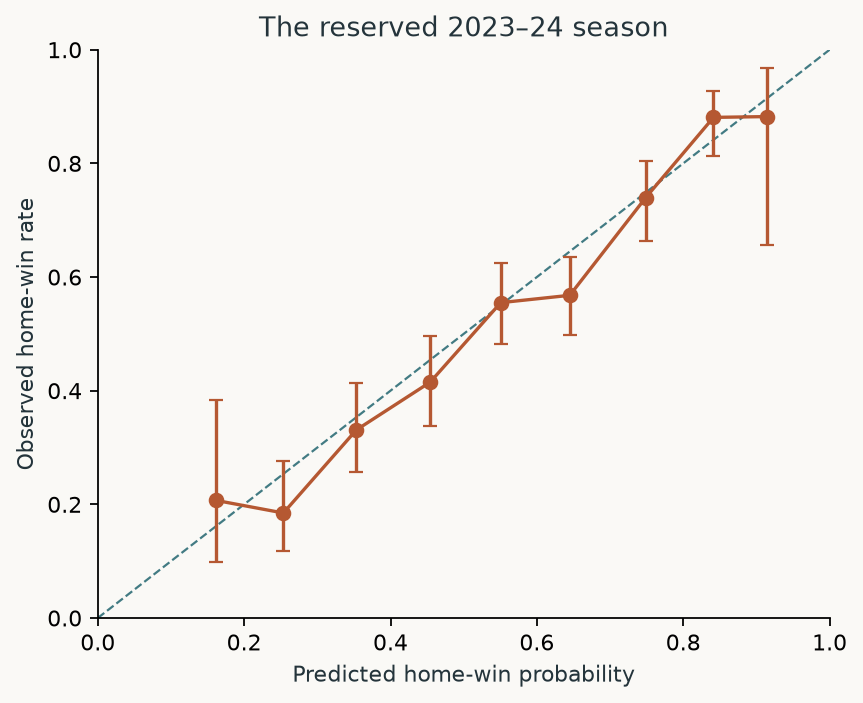

,bin,mean_probability,win_rate,n,lower,upper
0,"(0.1, 0.2]",0.162,0.207,29,0.098,0.384
1,"(0.2, 0.3]",0.254,0.185,92,0.119,0.276
2,"(0.3, 0.4]",0.353,0.331,136,0.257,0.414
3,"(0.4, 0.5]",0.454,0.415,147,0.338,0.496
4,"(0.5, 0.6]",0.551,0.555,182,0.482,0.625
5,"(0.6, 0.7]",0.645,0.568,199,0.498,0.635
6,"(0.7, 0.8]",0.749,0.740,146,0.663,0.804
7,"(0.8, 0.9]",0.841,0.881,126,0.813,0.927
8,"(0.9, 1.0]",0.914,0.882,17,0.657,0.967


{'predicted_home_win_rate': 0.5608, 'observed_home_win_rate': 0.5372, 'calibration_intercept': -0.1259, 'calibration_slope': 1.0583, 'calibration_ece': 0.0367}


In [3]:
display(Image(filename=str(ROOT / 'artifacts/figures/calibration.png')))
display(pd.read_csv(TABLES / 'test_calibration.csv').round(3))
print({key:round(results[key],4) for key in ['predicted_home_win_rate','observed_home_win_rate','calibration_intercept','calibration_slope','calibration_ece']})

The model predicts 56.1% home wins versus 53.7% observed. A diagnostic slope of 1.058 is near one; the intercept of −0.126 reflects an offset. These are diagnostics, not a recalibration fitted on test games. Extreme-probability bins are small.

## What makes one side the favorite?

,feature,coefficient,absolute_importance,odds_multiplier_per_sd,training_sd,coefficient_per_unit
0,net_rating_diff,0.498,0.498,1.645,7.203,0.069
1,win_pct_diff,0.215,0.215,1.240,0.226,0.951
2,back_to_back_diff,-0.114,0.114,0.892,0.516,-0.221
3,scoring_concentration_diff,0.093,0.093,1.098,0.023,4.090
4,weighted_absence_diff,-0.059,0.059,0.942,0.111,-0.536
5,weighted_ppa_diff,0.056,0.056,1.057,0.106,0.524
6,weighted_participation_diff,0.051,0.051,1.052,0.100,0.514
7,games_last7_diff,-0.048,0.048,0.953,0.837,-0.058
8,ft_rate_diff,-0.041,0.041,0.960,0.039,-1.054
9,dreb_rate_diff,0.030,0.030,1.030,0.025,1.185


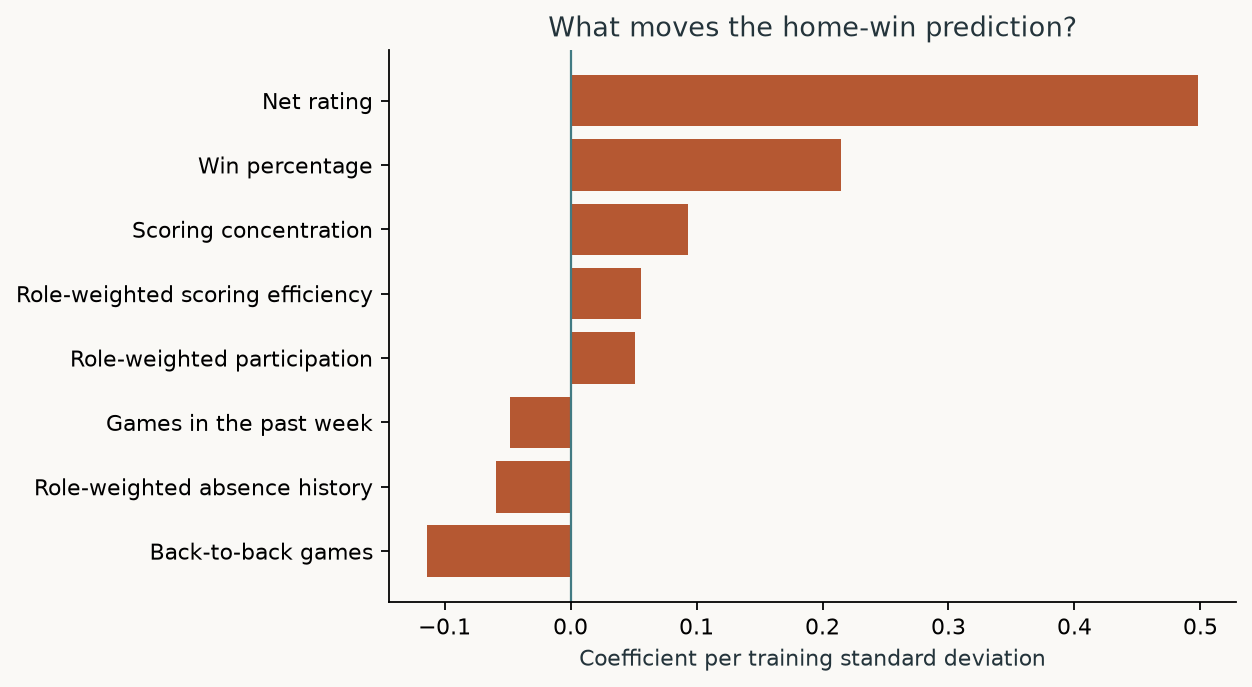

Nonzero coefficients: 19


In [4]:
importance=pd.read_csv(TABLES / 'importance.csv')
display(importance.head(10).round(3))
display(Image(filename=str(ROOT / 'artifacts/figures/model_inputs.png')))
print('Nonzero coefficients:',int(importance.coefficient.ne(0).sum()))

Season strength dominates. A one-training-standard-deviation increase in net-rating difference multiplies home-win odds by about 1.65, holding other inputs fixed. That is an odds change, not a 65-point probability change. Back-to-backs and prior absences work against the host. Nineteen of twenty-two coefficients are nonzero; minute continuity and top-five/top-seven shares shrink to zero.

## Which games exposed its limits?

In [5]:
misses=pd.read_csv(TABLES / 'biggest_misses.csv')
display(misses[['gamedate','away_off_team','home_off_team','away_points','home_points','probability']].head(8).round(3))
errors=pd.read_csv(TABLES / 'team_errors.csv')
display(pd.concat([errors.head(3),errors.tail(3)]).round(3))

,gamedate,away_off_team,home_off_team,away_points,home_points,probability
0,2024-04-12,DET,DAL,107,89,0.915
1,2024-01-22,CHA,MIN,128,125,0.912
2,2024-01-02,CHA,SAC,111,104,0.894
3,2024-01-28,OKC,DET,104,120,0.121
4,2023-11-27,POR,IND,114,110,0.869
5,2023-12-18,CHI,PHI,108,104,0.866
6,2023-11-20,BOS,CHA,118,121,0.134
7,2024-04-05,TOR,MIL,117,111,0.859


,team,predicted_win_rate,actual_win_rate,games,actual_minus_predicted
0,TOR,0.416,0.278,72,-0.138
1,WAS,0.278,0.181,72,-0.097
2,BKN,0.462,0.366,71,-0.096
27,NOP,0.563,0.625,72,0.062
28,PHX,0.561,0.625,72,0.064
29,LAL,0.522,0.592,71,0.070


Dallas against Detroit on April 12 is the largest miss: a 91.5% home favorite lost 89–107. Minnesota against Charlotte on January 22 is another. Toronto won substantially less often than predicted. These files alone cannot explain misses using late lineup changes, injuries or tactical narratives.

## Where did player histories change the view?

In [6]:
changes=pd.read_csv(TABLES / 'player_prediction_changes.csv')
display(changes[['gamedate','home_off_team','away_off_team','L1 team C=0.1','L1 team_players C=0.1','probability_change','weighted_absence_diff','y']].head(8).round(3))

,gamedate,home_off_team,away_off_team,L1 team C=0.1,L1 team_players C=0.1,probability_change,weighted_absence_diff,y
0,2023-04-09,WAS,HOU,0.737,0.575,-0.162,0.335,0
1,2023-04-07,CHA,HOU,0.642,0.489,-0.153,0.362,0
2,2022-02-08,BKN,BOS,0.523,0.374,-0.149,0.273,0
3,2022-01-07,LAL,ATL,0.566,0.711,0.145,-0.263,1
4,2020-01-05,CLE,MIN,0.454,0.589,0.136,-0.236,0
5,2021-05-14,GSW,NOP,0.648,0.783,0.135,-0.065,1
6,2022-01-09,LAL,MEM,0.554,0.687,0.133,-0.175,0
7,2022-12-30,NOP,PHI,0.621,0.491,-0.131,0.148,1


These development forecasts compare two separately fitted models with the same regularization setting. They show where player histories changed the forecast, without isolating a causal effect of any absence.

The useful result is a basketball model that improves on simple season-strength baselines in this test. Historical roster information, a ten-game warmup and one independent test season remain clear limitations.